# 04 · Caso 2 — múltiplos poços offshore: rede e simulação

Reprodução da Seção 4.2 do artigo: Tabelas 7–12, Figs. 9–10 (topologia e digrafo) e
Figs. 11–12 (curvas de nível da pressão de fundo dos poços 1/2 e 3/4). Quatro poços com
gas lift compartilham a linha de produção e o riser: os poços 1 e 2 entram no nó 1 e os
poços 3 e 4 no nó 2.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
REF = ROOT / "data" / "reference"
FIG = ROOT / "docs" / "paper" / "figures"
pd.set_option("display.precision", 4)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (7, 5), "axes.grid": True, "grid.alpha": 0.3})

In [2]:
from gaslift import case2_multi_well, SimulationOptions, ModelOptions, IntegrationOptions
from gaslift.plotting import plot_case_topology, plot_digraph, plot_rate_contours
from gaslift.sweeps import sweep_rates

case = case2_multi_well()
net = case.network
print(net)
print(f"Unknowns / equations: 3N + 4S = {net.layout.size}  (N = {net.n_nodes}, S = {net.n_pipes});"
      f" specifications: {case.specifications.count}")

Network(name='Case 2 - offshore multiple wells', nodes=28, pipes=27, wells=4)
Unknowns / equations: 3N + 4S = 192  (N = 28, S = 27); specifications: 55


> O artigo afirma que o modelo deste caso tem 232 equações; com N = 28 nós e S = 27 linhas,
> 3N + 4S = 192. O valor 232 (e a decomposição "27 + 27 + 27 + 56 + 95") não corresponde à
> formulação da Seção 3.3.

## Tabelas 7–12 · Linhas, perfis, nós e especificações

In [3]:
from gaslift.units import INCH

def pipes_table(case):
    net = case.network
    rows = []
    for p in net.pipes:
        g = p.geometry
        angles = np.degrees(g.segment_angles)
        incl = f"{angles[0]:.0f}°" if np.allclose(angles, angles[0]) else "profile"
        rows.append({"Line": case.paper_pipe_numbers[p.name], "Name": p.name, "Type": p.category.value,
                     "Diameter (in)": g.inlet_diameter / INCH, "Length (m)": g.length,
                     "Inclination": incl, "Roughness (µm)": g.roughness[0] * 1e6})
    return pd.DataFrame(rows).set_index("Line")

def nodes_table(case):
    net = case.network
    rows = [{"Node": case.paper_node_numbers[n.name], "Name": n.name, "Role": n.role.value,
             "X (m)": n.x, "Y (m)": n.y, "Height (m)": n.z} for n in net.nodes]
    return pd.DataFrame(rows).set_index("Node")

def profile_table(case, pipe):
    g = case.network.pipe(pipe).geometry
    return pd.DataFrame({"Length (m)": g.cumulative_lengths, "Height (m)": g.points[:, 2],
                         "x (m)": g.points[:, 0], "y (m)": g.points[:, 1]}).T

def specs_table(case):
    rows = []
    for name, s in case.specifications.items():
        parts = []
        if s.pressure is not None: parts.append(f"P = {s.pressure / 1e5:g} bar")
        if s.liquid_flow is not None: parts.append(f"wL = {s.liquid_flow:g} kg/s")
        if s.gas_flow is not None: parts.append(f"wG = {s.gas_flow:g} kg/s")
        rows.append({"Node": case.paper_node_numbers[name], "Name": name, "Specifications": "; ".join(parts)})
    return pd.DataFrame(rows).set_index("Node")

pipes_table(case)

,Name,Type,Diameter (in),Length (m),Inclination,Roughness (µm)
Line,,,,,,
1,production_line_1,production,6.0000,1500.0000,0°,100.0
2,production_line_2,production,6.0000,2504.9876,profile,100.0
3,riser,production,6.0000,1500.0000,90°,100.0
4,well_1:flowline,flowline,4.0000,500.0000,0°,100.0
5,well_1:wellbore_upper,wellbore,4.0000,1710.0000,90°,100.0
6,well_1:wellbore_lower,wellbore,4.0000,338.0000,90°,100.0
7,well_1:annulus,annulus,8.2857,1710.0000,90°,100.0
8,well_1:gas_line_1,gas,2.0000,4505.0126,profile,0.0
9,well_1:gas_line_2,gas,2.0000,1515.0000,-90°,0.0


In [4]:
display(profile_table(case, "well_1:gas_line_1").rename_axis("Lines 8 and 14 (Table 9)"))
display(profile_table(case, "well_3:gas_line_1").rename_axis("Lines 20 and 26 (Table 10)"))

,0,1,2,3,4
Lines 8 and 14 (Table 9),,,,,
Length (m),0.0,1004.9876,2504.9876,4004.9876,4505.0126
Height (m),-1495.0,-1395.0000,-1395.0000,-1395.0000,-1400.0000
x (m),0.0,0.0000,0.0000,0.0000,400.0000
y (m),4000.0,3000.0000,1500.0000,0.0000,-300.0000


,0,1,2,3
Lines 20 and 26 (Table 10),,,,
Length (m),0.0,1004.9876,2504.9876,3005.0126
Height (m),-1495.0,-1395.0000,-1395.0000,-1400.0000
x (m),0.0,0.0000,0.0000,400.0000
y (m),4000.0,3000.0000,1500.0000,1200.0000


> A Tabela 10 do artigo lista comprimentos acumulados 0, 1005, 2505 e 4005 m para as linhas
> 20 e 26; a geometria real (e a Tabela 16, que usa $L_{G3} = L_{G4} = 4520$ m) corresponde a
> 3005 m + 1515 m.

In [5]:
display(nodes_table(case))
display(specs_table(case))

,Name,Role,X (m),Y (m),Height (m)
Node,,,,,
1,manifold_1,connection,0.0,0.0,-1400.0
2,manifold_2,connection,0.0,1500.0,-1400.0
3,riser_base,connection,0.0,4000.0,-1500.0
4,riser_top,outlet,0.0,4000.0,0.0
5,well_1:wellhead,wellhead,400.0,-300.0,-1400.0
6,well_1:injection_point,injection_point,400.0,-300.0,-3110.0
7,well_1:downhole,downhole,400.0,-300.0,-3448.0
8,well_1:annulus_top,annulus_top,400.0,-300.0,-1400.0
9,well_1:gas_junction,gas_junction,0.0,4000.0,-1495.0


,Name,Specifications
Node,,
1,manifold_1,wL = 0 kg/s; wG = 0 kg/s
2,manifold_2,wL = 0 kg/s; wG = 0 kg/s
3,riser_base,wL = 0 kg/s; wG = 0 kg/s
4,riser_top,P = 15 bar
5,well_1:wellhead,wL = 0 kg/s; wG = 0 kg/s
6,well_1:injection_point,wL = 0 kg/s; wG = 0 kg/s
7,well_1:downhole,wL = 3 kg/s; wG = 1e-06 kg/s
8,well_1:annulus_top,wL = 0 kg/s; wG = 0 kg/s
9,well_1:gas_junction,wL = 0 kg/s; wG = 0 kg/s


## Fig. 9 · Projeção isométrica

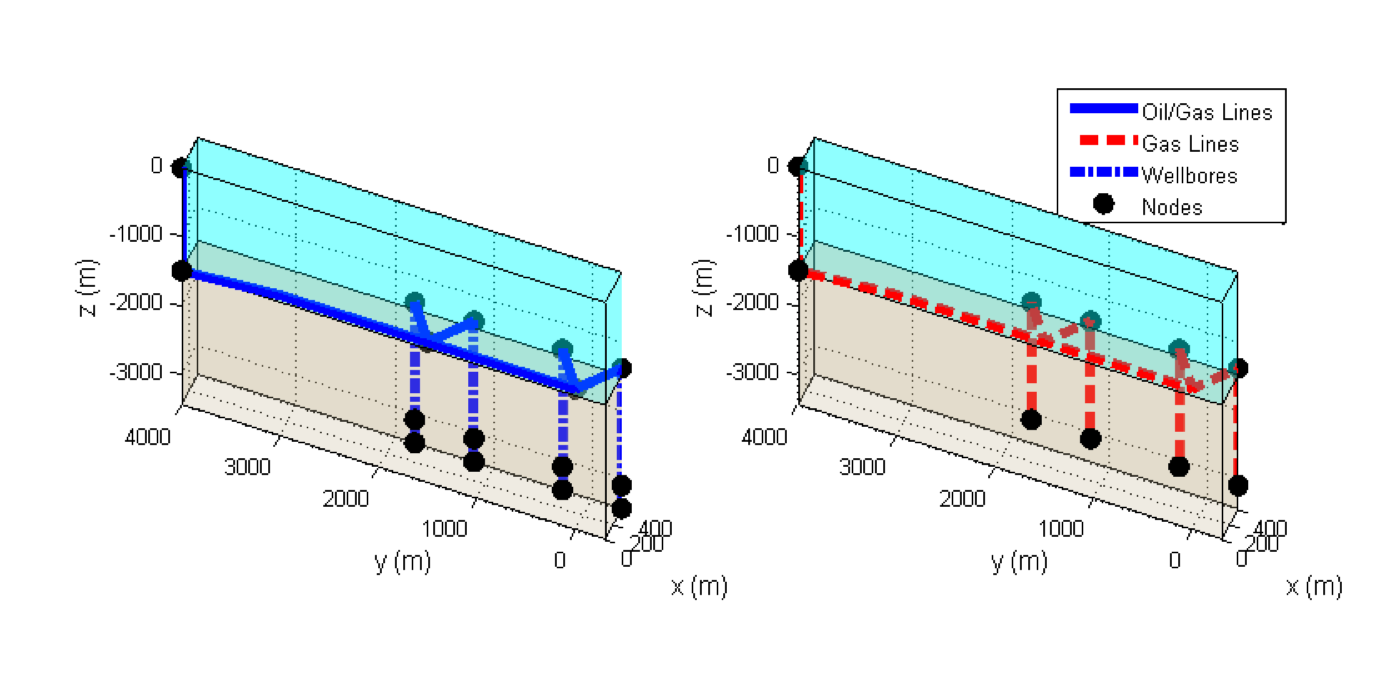

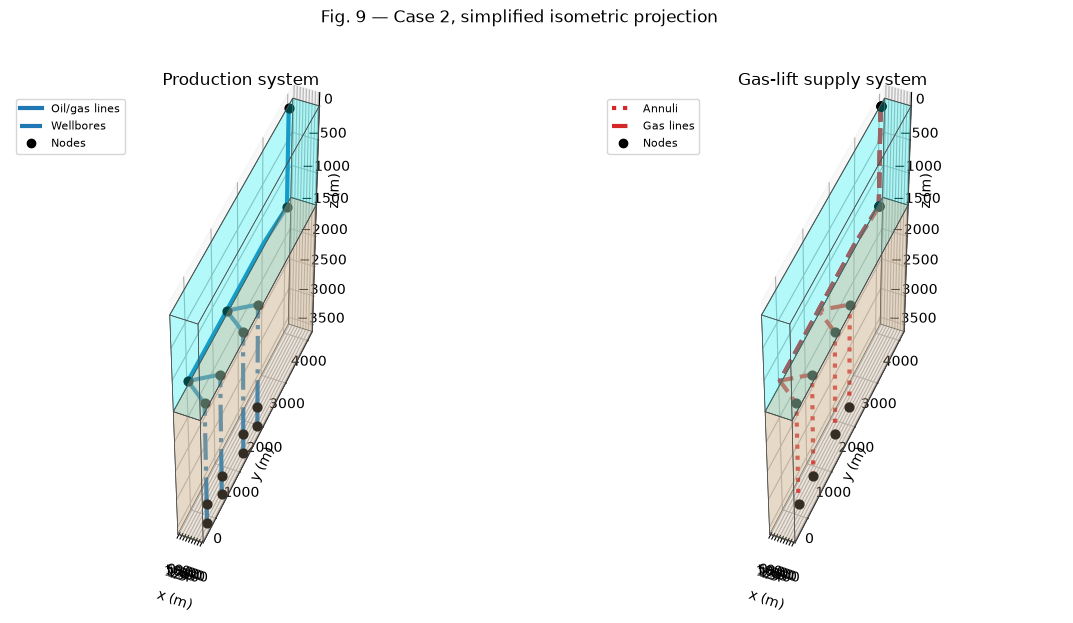

In [6]:
fig = plot_case_topology(net)
fig.suptitle("Fig. 9 — Case 2, simplified isometric projection", y=1.02);
display(Image(filename=str(FIG / "FIG_09.png"), width=900))

## Fig. 10 · Digrafo

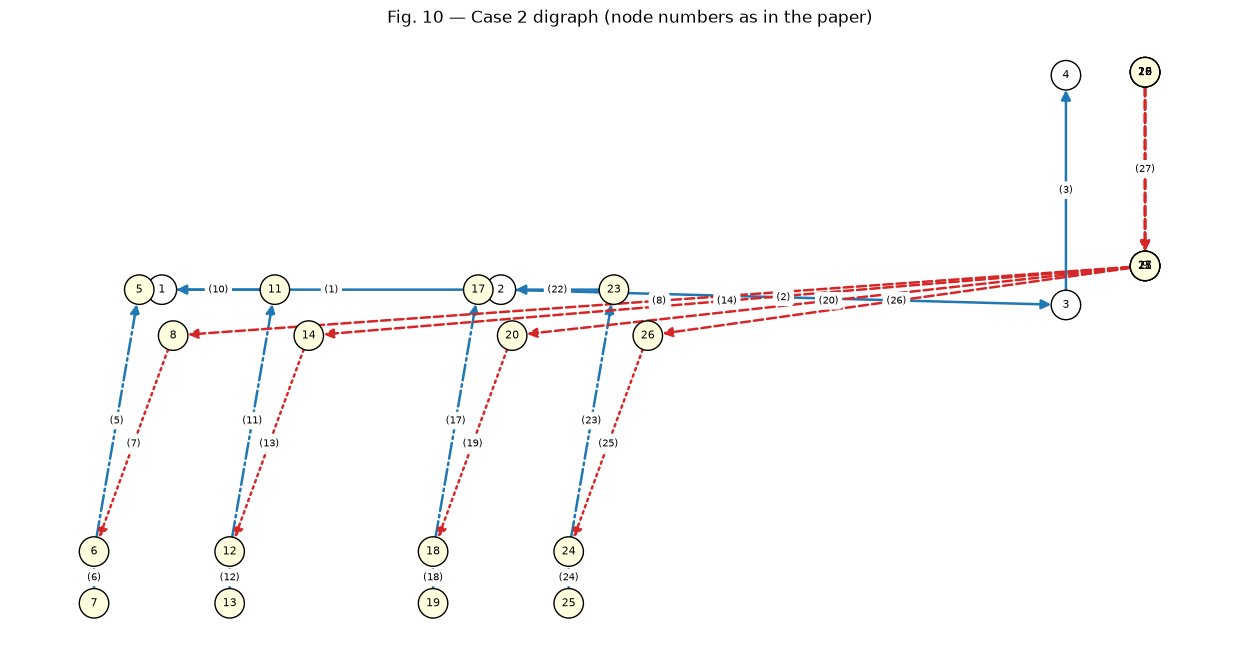

In [7]:
fig, ax = plt.subplots(figsize=(16, 8))
plot_digraph(net, ax, node_numbers=case.paper_node_numbers, pipe_numbers=case.paper_pipe_numbers)
ax.set_title("Fig. 10 — Case 2 digraph (node numbers as in the paper)");

## Simulação de um ponto de operação: 3 kg/s de óleo e 1 kg/s de gás por poço

In [8]:
sol = case.simulator().solve()
print(sol.status)
display(sol.wells_table())
sol.pipes_table()[["category", "length_m", "liquid_flow_kg_s", "gas_flow_kg_s", "inlet_pressure_bar", "outlet_pressure_bar", "dominant_pattern"]]

converged (residual below tolerance) after 4 iterations, |F| = 1.606e-11, 0.12 s


,oil_rate_kg_s,gas_injection_kg_s,downhole_pressure_bar,injection_point_pressure_bar,wellhead_pressure_bar,gas_inlet_pressure_bar
well,,,,,,
well_1,3.0,1.0,188.5422,160.2498,86.4020,193.2707
well_2,3.0,1.0,188.5422,160.2498,86.4020,193.2707
well_3,3.0,1.0,185.6510,157.3586,84.0035,182.7084
well_4,3.0,1.0,185.6510,157.3586,84.0035,182.7084


,category,length_m,liquid_flow_kg_s,gas_flow_kg_s,inlet_pressure_bar,outlet_pressure_bar,dominant_pattern
pipe,,,,,,,
production_line_1,production,1500.0000,6.0000e+00,2.0000e+00,84.7682,82.3330,intermittent
production_line_2,production,2504.9876,1.2000e+01,4.0000e+00,82.3330,70.0299,intermittent
riser,production,1500.0000,1.2000e+01,4.0000e+00,70.0299,15.0000,intermittent
well_1:flowline,flowline,500.0000,3.0000e+00,1.0000e+00,86.4020,84.7682,intermittent
well_1:wellbore_upper,wellbore,1710.0000,3.0000e+00,1.0000e+00,160.2498,86.4020,intermittent
well_1:wellbore_lower,wellbore,338.0000,3.0000e+00,1.0000e-06,188.5422,160.2498,intermittent
well_1:annulus,annulus,1710.0000,1.0000e-06,1.0000e+00,181.0345,160.2498,segregated
well_1:gas_line_1,gas,4505.0126,1.0000e-06,1.0000e+00,210.4118,181.0345,distributed
well_1:gas_line_2,gas,1515.0000,1.0000e-06,1.0000e+00,193.2707,210.4118,distributed


## Figs. 11 e 12 · Varredura de vazões

Gás injetado de 0,25 a 4 kg/s e óleo de 0,5 a 8 kg/s, iguais em todos os poços
(256 simulações de 192 incógnitas; tolerância de integração `1e-2`, como no original).

In [9]:
import time
q_gas = np.arange(0.25, 4.01, 0.25)
q_oil = np.arange(0.5, 8.01, 0.5)
opts = SimulationOptions(model=ModelOptions(integration=IntegrationOptions(rtol=1e-2)), compute_profiles=False)
t0 = time.perf_counter()
sweep = sweep_rates(case2_multi_well(), q_gas, q_oil, opts)
print(f"{sweep.converged.sum()} of {sweep.converged.size} points converged in {time.perf_counter() - t0:.1f} s")

247 of 256 points converged in 96.3 s


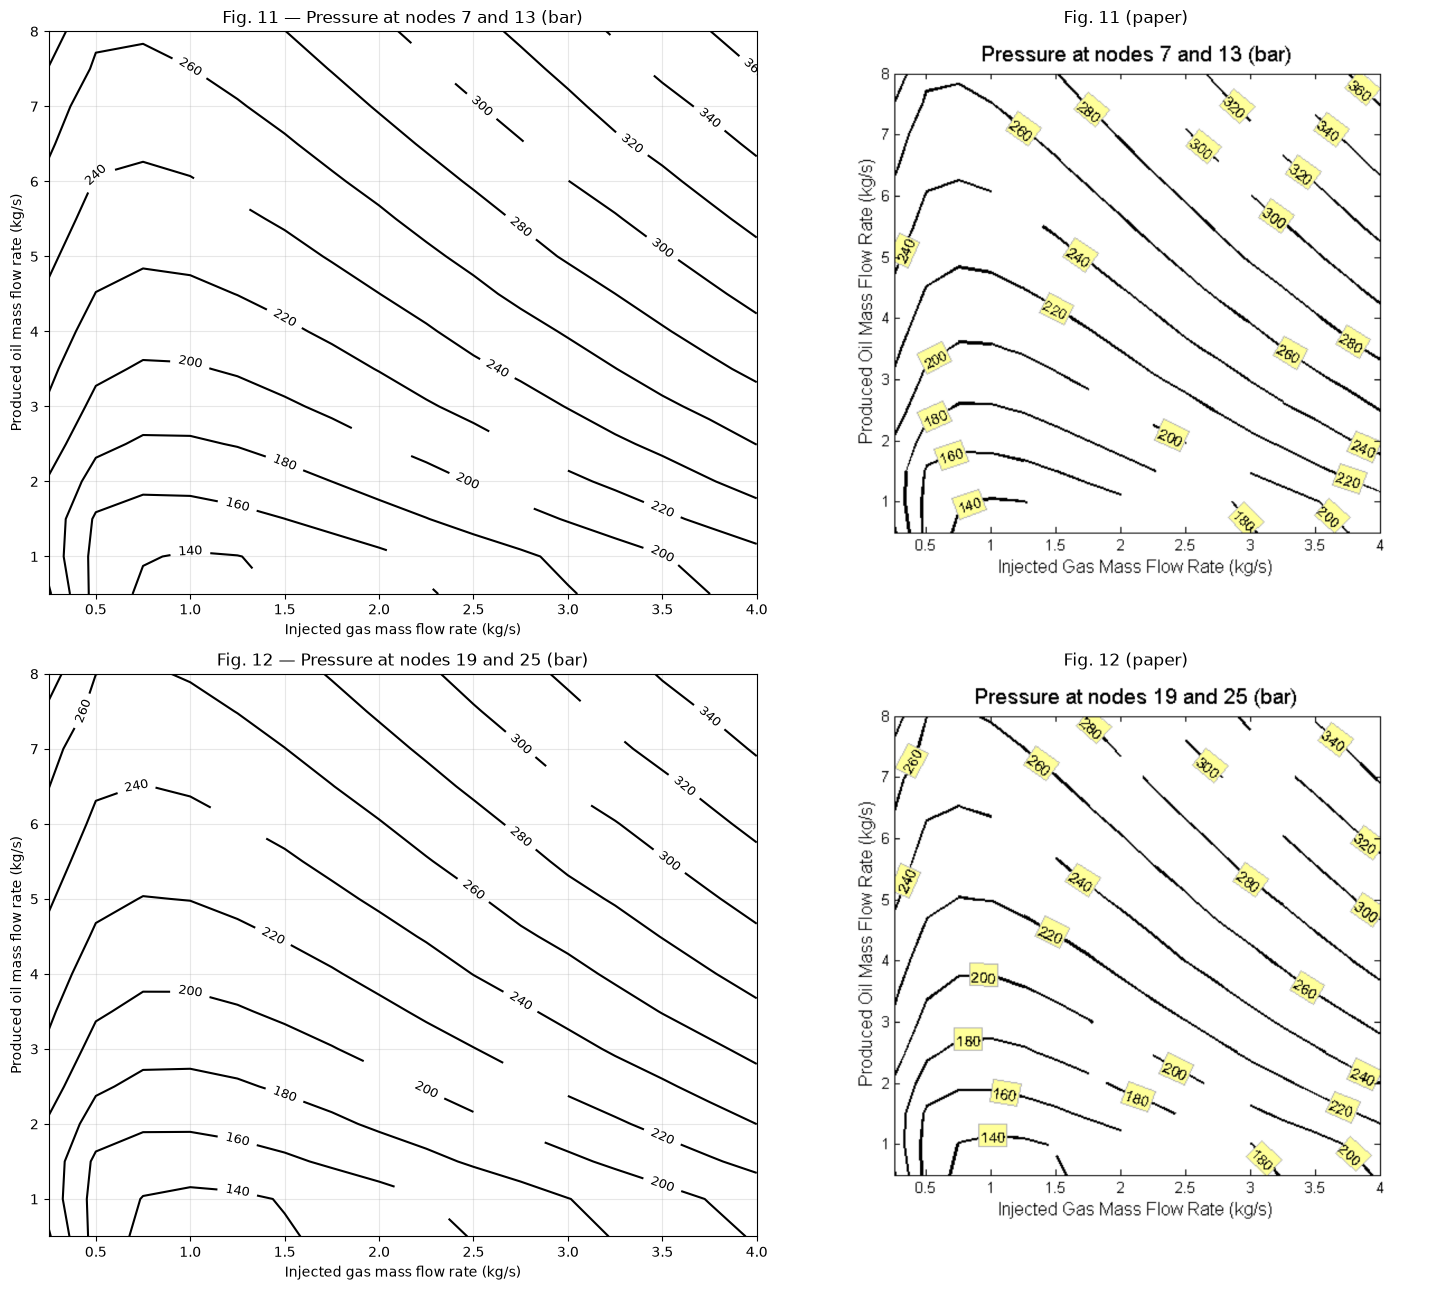

In [10]:
levels = np.arange(140, 380, 20)
fig, axes = plt.subplots(2, 2, figsize=(15, 13))
plot_rate_contours(sweep.q_gas, sweep.q_oil, sweep.downhole(0), axes[0, 0], levels, title="Fig. 11 — Pressure at nodes 7 and 13 (bar)")
axes[0, 1].imshow(plt.imread(FIG / "FIG_11.png")); axes[0, 1].axis("off"); axes[0, 1].set_title("Fig. 11 (paper)")
plot_rate_contours(sweep.q_gas, sweep.q_oil, sweep.downhole(2), axes[1, 0], levels, title="Fig. 12 — Pressure at nodes 19 and 25 (bar)")
axes[1, 1].imshow(plt.imread(FIG / "FIG_12.png")); axes[1, 1].axis("off"); axes[1, 1].set_title("Fig. 12 (paper)")
plt.tight_layout()

## Validação contra os resultados MATLAB originais

In [11]:
import json
ref = json.load(open(REF / "case2_grid.json"))
ref_p = np.array([[[np.nan] * 4 if c is None else c for c in row] for row in ref["p_downhole_bar"]], dtype=float)
diff = np.abs(sweep.downhole_pressure - ref_p)
both = np.isfinite(diff[:, :, 0])
print(f"MATLAB reference: {np.isfinite(ref_p[:, :, 0]).sum()} converged points; Python: {sweep.converged.sum()}; common: {both.sum()}")
print(f"max |ΔP_downhole| over common points: {np.nanmax(diff):.3f} bar; 99th percentile: {np.nanpercentile(diff, 99):.2e} bar")
pd.DataFrame(diff[:, :, 0], index=sweep.q_oil, columns=sweep.q_gas).rename_axis(index="q_oil", columns="q_gas").style.format("{:.1e}")

MATLAB reference: 248 converged points; Python: 247; common: 246
max |ΔP_downhole| over common points: 0.000 bar; 99th percentile: 2.45e-07 bar


q_gas,0.250000,0.500000,0.750000,1.000000,1.250000,1.500000,1.750000,2.000000,2.250000,2.500000,2.750000,3.000000,3.250000,3.500000,3.750000,4.000000
q_oil,,,,,,,,,,,,,,,,
0.500000,3.3e-08,2.0e-08,1.6e-08,2.8e-08,nan,4.9e-08,5.3e-08,7.2e-08,8.5e-08,1.0e-07,1.2e-07,1.3e-07,1.5e-07,1.7e-07,1.9e-07,2.1e-07
1.000000,3.9e-09,1.3e-08,2.3e-08,3.3e-08,3.8e-08,4.7e-08,6.0e-08,7.6e-08,nan,9.7e-08,1.2e-07,1.3e-07,1.5e-07,1.8e-07,1.9e-07,2.1e-07
1.500000,4.2e-09,1.2e-08,2.1e-08,3.0e-08,4.0e-08,4.9e-08,6.4e-08,7.4e-08,7.4e-08,1.1e-07,nan,1.3e-07,1.5e-07,1.7e-07,1.8e-07,2.1e-07
2.000000,3.8e-09,1.2e-08,2.1e-08,3.1e-08,3.8e-08,5.1e-08,6.3e-08,7.9e-08,7.5e-08,1.1e-07,nan,1.4e-07,1.6e-07,1.5e-07,1.7e-07,2.3e-07
2.500000,3.8e-09,1.2e-08,2.2e-08,3.1e-08,4.0e-08,5.1e-08,6.2e-08,nan,5.0e-08,7.0e-08,nan,1.4e-07,1.6e-07,1.7e-07,1.8e-07,2.3e-07
3.000000,3.9e-09,1.2e-08,2.2e-08,3.2e-08,4.1e-08,5.2e-08,4.0e-08,7.1e-08,9.6e-08,1.0e-07,1.2e-07,1.1e-07,1.6e-07,1.8e-07,2.0e-07,2.2e-07
3.500000,3.9e-09,1.2e-08,2.2e-08,3.2e-08,4.2e-08,5.3e-08,6.6e-08,6.3e-08,9.2e-08,1.0e-07,1.2e-07,1.2e-07,1.6e-07,1.4e-07,2.1e-07,2.5e-07
4.000000,3.9e-09,1.2e-08,2.2e-08,3.2e-08,4.2e-08,5.3e-08,6.1e-08,7.5e-08,6.4e-08,1.2e-07,8.0e-08,1.2e-07,1.6e-07,1.8e-07,2.0e-07,2.2e-07
4.500000,4.0e-09,1.2e-08,2.2e-08,3.3e-08,4.3e-08,5.4e-08,5.3e-08,7.9e-08,7.8e-08,8.1e-08,1.4e-07,1.4e-07,1.6e-07,1.6e-07,2.0e-07,2.0e-07
